# MiniVLA closed-loop rollouts

Single-step regression metrics are not enough for robotics. This notebook repeatedly feeds predictions back into the simulated robot state and asks whether the policy both:

1. reaches the instructed target within the configured tolerance; and
2. issues the correct gripper-close command.

The visual observation is re-rendered after every action so its end-effector marker stays consistent with the numerical state.

In [1]:
from pathlib import Path
from dataclasses import replace
import sys
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataset import SyntheticTabletopDataset
from src.evaluate import load_trained_model
from src.utils import load_config, seed_everything

config = load_config(ROOT / 'configs' / 'default.yaml')
seed_everything(int(config['seed']))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dataset = SyntheticTabletopDataset.from_config(config, 'test')
model = load_trained_model(config, device, attention='sdpa').eval()
settings = config['benchmark']
max_steps = int(settings['rollout_steps'])
tolerance = float(settings['rollout_tolerance'])
print(f'Device: {device} | test scenes: {len(dataset)} | max steps: {max_steps} | tolerance: {tolerance}')

Device: cuda | test scenes: 400 | max steps: 12 | tolerance: 0.1


## Roll out a fixed mini-suite

The following function batches scenes for efficient inference but keeps a full trajectory, target distance, and gripper-probability trace for every task. Success is latched only when position and gripper criteria are simultaneously satisfied.

In [2]:
@torch.inference_mode()
def run_rollouts(indices):
    scenes = [dataset.scene(index) for index in indices]
    states = torch.tensor([scene.end_effector for scene in scenes], dtype=torch.float32, device=device)
    targets = torch.tensor(
        [scene.objects[scene.target_index].position for scene in scenes], dtype=torch.float32, device=device
    )
    encoded = [dataset.tokenizer.encode(scene.instruction) for scene in scenes]
    token_ids = torch.stack([item[0] for item in encoded]).to(device)
    token_mask = torch.stack([item[1] for item in encoded]).to(device)
    trajectories = [states.cpu().numpy().copy()]
    gripper_probabilities = []
    distances = []
    succeeded = torch.zeros(len(indices), dtype=torch.bool, device=device)
    success_step = torch.full((len(indices),), -1, dtype=torch.long, device=device)

    for step in range(max_steps):
        state_array = states.cpu().numpy()
        rendered = []
        for row, scene in enumerate(scenes):
            updated_scene = replace(scene, end_effector=(float(state_array[row, 0]), float(state_array[row, 1])))
            rendered.append(np.asarray(dataset.render(updated_scene), dtype=np.float32) / 255.0)
        images = torch.from_numpy(np.stack(rendered)).permute(0, 3, 1, 2).contiguous().to(device)
        actions = model.predict_actions(images, token_ids, token_mask, states).float()
        already_succeeded = succeeded.clone()
        proposed_states = torch.clamp(states + actions[:, :2], 0.0, 1.0)
        states = torch.where(already_succeeded[:, None], states, proposed_states)
        distance = torch.linalg.vector_norm(states - targets, dim=1)
        reached_and_closed = (distance <= tolerance) & (actions[:, 2] >= 0.5)
        newly_succeeded = reached_and_closed & ~succeeded
        success_step[newly_succeeded] = step + 1
        succeeded |= reached_and_closed
        trajectories.append(states.cpu().numpy().copy())
        gripper_probabilities.append(actions[:, 2].cpu().numpy().copy())
        distances.append(distance.cpu().numpy().copy())

    return {
        'indices': np.asarray(indices),
        'scenes': scenes,
        'targets': targets.cpu().numpy(),
        'trajectories': np.stack(trajectories, axis=1),
        'gripper': np.stack(gripper_probabilities, axis=1),
        'distances': np.stack(distances, axis=1),
        'succeeded': succeeded.cpu().numpy(),
        'success_step': success_step.cpu().numpy(),
    }

suite = run_rollouts(list(range(32)))
print(f"Mini-suite success: {suite['succeeded'].sum()}/{len(suite['indices'])} "
      f"({100.0 * suite['succeeded'].mean():.1f}%)")
print('Successful scene indices:', suite['indices'][suite['succeeded']].tolist())

Mini-suite success: 8/32 (25.0%)
Successful scene indices: [4, 10, 13, 15, 19, 20, 22, 27]


## Inspect successes and failures

Gold stars mark targets, black crosses mark starting states, and magenta lines show the learned closed-loop trajectory. The selected gallery includes both successful and unsuccessful tasks whenever the mini-suite contains both.

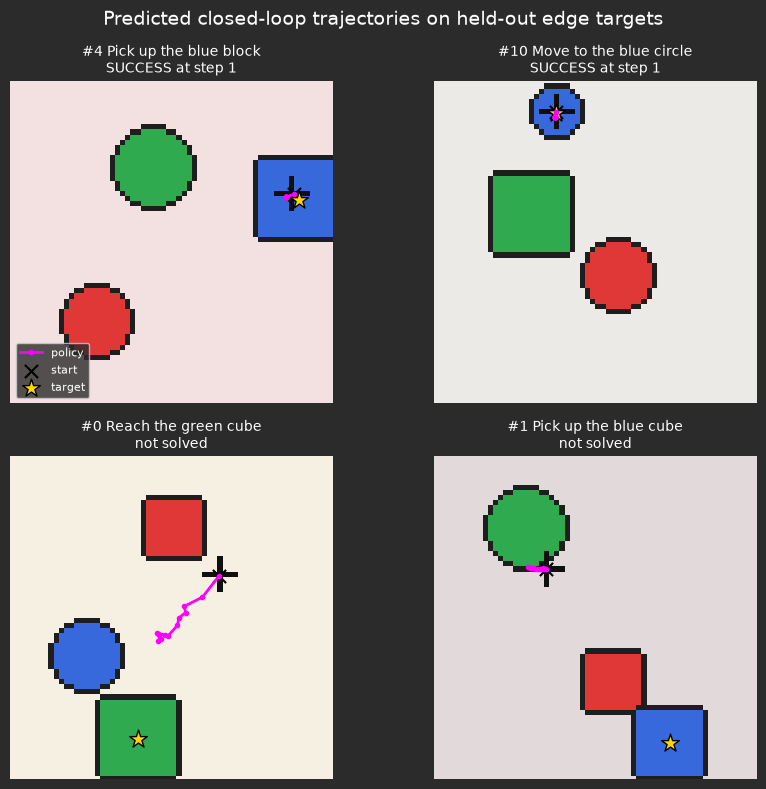

In [3]:
successful_rows = np.flatnonzero(suite['succeeded']).tolist()
failed_rows = np.flatnonzero(~suite['succeeded']).tolist()
selected_rows = (successful_rows[:2] + failed_rows[:2])
for row in range(len(suite['indices'])):
    if len(selected_rows) >= 4:
        break
    if row not in selected_rows:
        selected_rows.append(row)

figure, axes = plt.subplots(2, 2, figsize=(9, 8))
for axis, row in zip(axes.flat, selected_rows):
    scene = suite['scenes'][row]
    axis.imshow(dataset.render(scene))
    trajectory = suite['trajectories'][row] * 63
    target = suite['targets'][row] * 63
    axis.plot(trajectory[:, 0], trajectory[:, 1], '-o', color='magenta', markersize=3, linewidth=2, label='policy')
    axis.scatter(trajectory[0, 0], trajectory[0, 1], marker='x', s=90, c='black', label='start')
    axis.scatter(target[0], target[1], marker='*', s=180, c='gold', edgecolors='black', label='target')
    status = 'SUCCESS' if suite['succeeded'][row] else 'not solved'
    step = suite['success_step'][row]
    suffix = f' at step {step}' if step >= 0 else ''
    axis.set_title(f"#{suite['indices'][row]} {scene.instruction}\n{status}{suffix}", fontsize=10)
    axis.set_xlim(0, 63)
    axis.set_ylim(63, 0)
    axis.axis('off')
axes.flat[0].legend(loc='lower left', fontsize=8)
figure.suptitle('Predicted closed-loop trajectories on held-out edge targets', fontsize=14)
figure.tight_layout()
plt.show()

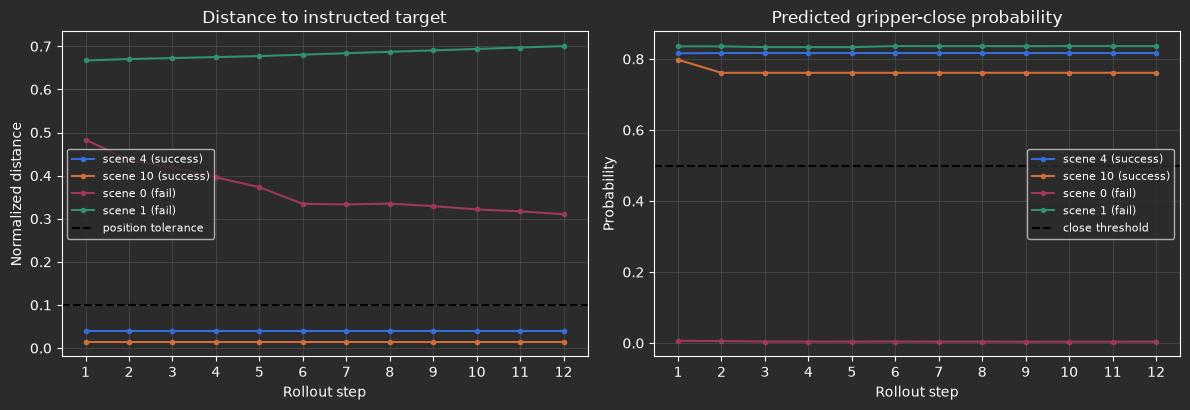

In [4]:
steps = np.arange(1, max_steps + 1)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for row in selected_rows:
    label = f"scene {suite['indices'][row]} ({'success' if suite['succeeded'][row] else 'fail'})"
    axes[0].plot(steps, suite['distances'][row], marker='o', markersize=3, label=label)
    axes[1].plot(steps, suite['gripper'][row], marker='o', markersize=3, label=label)
axes[0].axhline(tolerance, color='black', linestyle='--', label='position tolerance')
axes[1].axhline(0.5, color='black', linestyle='--', label='close threshold')
axes[0].set(title='Distance to instructed target', xlabel='Rollout step', ylabel='Normalized distance')
axes[1].set(title='Predicted gripper-close probability', xlabel='Rollout step', ylabel='Probability')
for axis in axes:
    axis.set_xticks(steps)
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
figure.tight_layout()
plt.show()

In [5]:
print(f"{'scene':>5} {'result':>9} {'final dist':>11} {'max grip p':>11}  instruction")
for row in selected_rows:
    result = 'success' if suite['succeeded'][row] else 'failed'
    print(f"{suite['indices'][row]:>5} {result:>9} {suite['distances'][row, -1]:>11.3f} "
          f"{suite['gripper'][row].max():>11.3f}  {suite['scenes'][row].instruction}")

scene    result  final dist  max grip p  instruction
    4   success       0.039       0.817  Pick up the blue block
   10   success       0.015       0.798  Move to the blue circle
    0    failed       0.310       0.006  Reach the green cube
    1    failed       0.700       0.836  Pick up the blue cube


### Why the rollout metric matters

A low one-step MSE can still produce compounding position error, premature gripper closure, or a policy that reaches the object but never grasps. These traces make failure modes visible. The synthetic task is deliberately simple—there is no collision, depth, or grasp physics—but the evaluation pattern carries directly to richer closed-loop VLA systems.